<a href="https://colab.research.google.com/github/UdeshiEdirisinghe25/AL-ZScore-Predictor/blob/main/ML_Zscore_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# A/L Z-SCORE PREDICTION
#install libraries

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gdown

In [4]:
# 2. LOAD A/L STUDENT PERFORMANCE DATASET

AL_ID = "133YoMk3jFbUSnXx1lR1VwFyPHnuMZ41N"
gdown.download(id=AL_ID, output="al_results.csv", quiet=False)

al_df = pd.read_csv("al_results.csv")

print("\nDataset loaded successfully!")
print("Shape:", al_df.shape)
print("Columns:", al_df.columns.tolist())
display(al_df.head())

Downloading...
From: https://drive.google.com/uc?id=133YoMk3jFbUSnXx1lR1VwFyPHnuMZ41N
To: /content/al_results.csv
100%|██████████| 42.5M/42.5M [00:00<00:00, 59.3MB/s]



Dataset loaded successfully!
Shape: (337553, 19)
Columns: ['index', 'stream', 'Zscore', 'district_rank', 'island_rank', 'al_year', 'sub1', 'sub1_r', 'sub2', 'sub2_r', 'sub3', 'sub3_r', 'cgt_r', 'ge_r', 'syllabus', 'birth_day', 'birth_month', 'birth_year', 'gender']


,index,stream,Zscore,district_rank,island_rank,al_year,sub1,sub1_r,sub2,sub2_r,sub3,sub3_r,cgt_r,ge_r,syllabus,birth_day,birth_month,birth_year,gender
0,0,ARTS,-0.355,4336 (NEW),64994 (NEW),2020,POLITICAL SCIENCE,S,DANCING(BHARATHA),C,TAMIL,S,056,S,new,31,May,2001,female
1,1,ARTS,-0.2648,4154 (NEW),62338 (NEW),2020,POLITICAL SCIENCE,S,CARNATIC MUSIC,C,TAMIL,C,032,C,new,13,January,2002,female
2,2,COMMERCE,-0.476,6910 (NEW),37307 (NEW),2020,ECONOMICS,S,BUSINESS STUDIES,S,ACCOUNTING,S,050,S,new,16,August,2001,female
3,3,COMMERCE,-0.1012,5678 (NEW),30449 (NEW),2020,ECONOMICS,C,BUSINESS STUDIES,C,ACCOUNTING,S,034,S,new,16,August,2001,female
4,4,COMMERCE,0.6014,3269 (NEW),17010 (NEW),2020,ECONOMICS,C,BUSINESS STUDIES,C,ACCOUNTING,B,036,S,new,7,August,2000,female


In [5]:
# 2. CLEAN

GRADE_PTS = {"A": 4, "B": 3, "C": 2, "S": 1, "F": 0, "W": 0}

df_model = al_df.copy()
df_model["Zscore"] = pd.to_numeric(df_model["Zscore"], errors="coerce")
df_model["al_year"] = pd.to_numeric(df_model["al_year"], errors="coerce")
df_model = df_model.dropna(subset=["Zscore", "al_year", "sub1", "sub2", "sub3"]).reset_index(drop=True)


EXTRA_CATS = [c for c in ["district", "medium", "school_type", "gender"] if c in df_model.columns]

ALL_SUBJECTS = sorted(
    pd.concat([df_model[f"sub{i}"] for i in (1, 2, 3)])
    .astype(str).str.strip().str.replace(" ", "_").unique()
)

In [6]:
# 3. FEATURE ENGINEERING

def build_features(df):
    s, g, p = [], [], []
    for i in (1, 2, 3):
        s.append(df[f"sub{i}"].astype(str).str.strip().str.replace(" ", "_").values)
        gr = df[f"sub{i}_r"].astype(str).str.strip().str.upper()
        g.append(gr.values)
        p.append(gr.map(GRADE_PTS).fillna(0).values)
    s, g, p = np.array(s).T, np.array(g).T, np.array(p).T

    X = pd.DataFrame(index=range(len(df)))
    X["stream"] = df["stream"].astype(str).str.strip().values
    X["syllabus"] = df["syllabus"].astype(str).str.strip().values
    X["al_year"] = pd.to_numeric(df["al_year"], errors="coerce").values

    for c in EXTRA_CATS:
        X[c] = df[c].astype(str).values if c in df.columns else "unknown"

    combo = ["|".join(sorted(r)) for r in s]
    profile = ["|".join(sorted(f"{a}:{b}" for a, b in zip(rs, rg))) for rs, rg in zip(s, g)]
    X["combo"] = combo
    X["combo_year"] = [f"{c}_{int(y)}" for c, y in zip(combo, X["al_year"])]
    X["profile"] = profile
    X["profile_year"] = [f"{c}_{int(y)}" for c, y in zip(profile, X["al_year"])]

    X["total_pts"] = p.sum(1)
    X["max_pts"] = p.max(1)
    X["min_pts"] = p.min(1)

    subj_cols = {f"SUBJ_{sub}": ((s == sub) * p).sum(1) for sub in ALL_SUBJECTS}
    X = pd.concat([X, pd.DataFrame(subj_cols)], axis=1)
    return X


X = build_features(df_model)
y = df_model["Zscore"].reset_index(drop=True)
print("X:", X.shape, "| y:", y.shape)

cat_cols = ["stream", "syllabus", "combo", "combo_year", "profile", "profile_year"] + EXTRA_CATS
num_cols = [c for c in X.columns if c not in cat_cols]


X: (232304, 72) | y: (232304,)


In [7]:
# 4. SPLIT + PIPELINE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

pre = ColumnTransformer([
    ("cat", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=42), cat_cols),
    ("num", "passthrough", num_cols),
])

model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=1500,
    max_leaf_nodes=63,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=40,
    random_state=42,
)

pipeline = Pipeline([("preprocessor", pre), ("model", model)])

print("Training...")
pipeline.fit(X_train, y_train)

Training...


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['stream', 'syllabus',
                                                   'combo', 'combo_year',
                                                   'profile', 'profile_year',
                                                   'gender']),
                                                 ('num', 'passthrough',
                                                  ['al_year', 'total_pts',
                                                   'max_pts', 'min_pts',
                                                   'SUBJ_ACCOUNTING',
                                                   'SUBJ_AGRICULTURAL_SCIENCE',
                                                   'SUBJ_AGRO_TECHNOLOGY',
                                                   'SUBJ_ARABIC...
                                                   'SUBJ_DANCING(BHARATHA)',
                                                   'SUBJ_DANCING(INDIGENOUS)',
                                                   'SUBJ_DRAMA_AND_THEATRE_(ENGLISH)',
                                                   'SUBJ_DRAMA_AND_THEATRE_(SINHALA)',
                                                   'SUBJ_DRAMA_AND_THEATRE_(TAMIL)',
                                                   'SUBJ_ECONOMICS', ...])])),
                ('model',
                 HistGradientBoostingRegressor(early_stopping=True,
                                               l2_regularization=1.0,
                                               learning_rate=0.05,
                                               max_iter=1500, max_leaf_nodes=63,
                                               n_iter_no_change=40,
                                               random_state=42))])

Train: MAE=0.1177  RMSE=0.1487  R2=0.9620
Test: MAE=0.1264  RMSE=0.1588  R2=0.9572


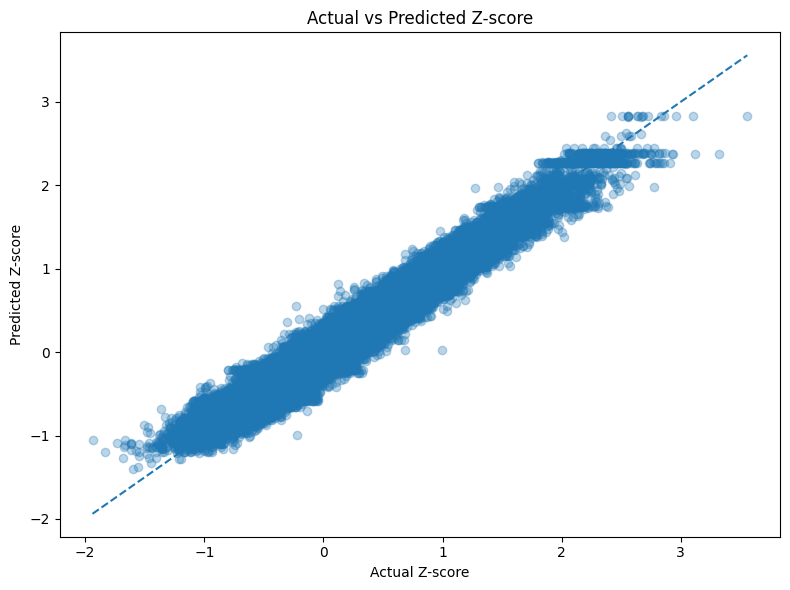

5-fold CV MAE: 0.1260 (+/- 0.0006)


In [8]:
# 5. EVALUATION

for name, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pr = pipeline.predict(Xs)
    print(f"{name}: MAE={mean_absolute_error(ys, pr):.4f}  "
          f"RMSE={np.sqrt(mean_squared_error(ys, pr)):.4f}  R2={r2_score(ys, pr):.4f}")

y_test_pred = pipeline.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.3)
lo, hi = min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())
plt.plot([lo, hi], [lo, hi], "--")
plt.xlabel("Actual Z-score"); plt.ylabel("Predicted Z-score")
plt.title("Actual vs Predicted Z-score"); plt.tight_layout(); plt.show()

cv = cross_val_score(pipeline, X, y, cv=KFold(5, shuffle=True, random_state=42),
                     scoring="neg_mean_absolute_error", n_jobs=-1)
print(f"5-fold CV MAE: {-cv.mean():.4f} (+/- {cv.std():.4f})")

In [9]:
# 6. NEW STUDENT FEATURES

def create_new_student_features(stream, subject1, grade1, subject2, grade2,
                                subject3, grade3, syllabus, al_year, **extras):
    row = {
        "stream": stream, "syllabus": syllabus, "al_year": al_year,
        "sub1": subject1, "sub1_r": grade1,
        "sub2": subject2, "sub2_r": grade2,
        "sub3": subject3, "sub3_r": grade3,
    }
    row.update(extras)   # e.g. district="Ratnapura"
    return build_features(pd.DataFrame([row]))[X.columns]

In [10]:
# HELPERS

import difflib

STREAM_ALIASES = {
    "maths": "physical science", "math": "physical science", "mathematics": "physical science",
    "combined maths": "physical science", "physical": "physical science", "physics": "physical science",
    "bio": "biological science", "biology": "biological science",
    "bio science": "biological science", "bio system": "biosystems technology",
    "biosystems": "biosystems technology", "bst": "biosystems technology",
    "eng tech": "engineering technology", "et": "engineering technology",
    "art": "arts", "commerce": "commerce", "com": "commerce",
}

def match_value(value, options, aliases=None, cutoff=0.8):
    opts = list(options)
    low = {o.lower(): o for o in opts}
    v = value.strip().lower()
    if aliases:
        v = aliases.get(v, v)
    if v in low:
        return low[v]
    contains = [o for o in opts if v and (v in o.lower())]
    if len(contains) == 1:
        return contains[0]
    close = difflib.get_close_matches(v, list(low.keys()), n=1, cutoff=cutoff)
    return low[close[0]] if close else None

In [12]:
# 7. USER INPUT + PREDICTION

streams  = sorted(df_model["stream"].astype(str).str.strip().unique())
syllabi  = sorted(df_model["syllabus"].astype(str).str.strip().unique())
years    = sorted(df_model["al_year"].dropna().astype(int).unique())
subj_lookup = {s.replace("_", " ").lower(): s.replace("_", " ") for s in ALL_SUBJECTS}


def ask(label, examples=None):
    if examples is not None:
        print(f"\n{label}   (e.g. {', '.join(map(str, examples))})")
    else:
        print(f"\n{label}")
    return input("   > ").strip()


def match(value, options):
    """Use the dataset's spelling if it matches, otherwise keep what was typed."""
    lookup = {str(o).lower(): o for o in options}
    return lookup.get(value.lower(), value)


print("\n🎓 A/L Z-SCORE PREDICTOR")

print("\nA/L stream")
print("   Options:", ", ".join(streams))
user_stream = input("   > ").strip()
user_stream = match_value(user_stream, streams, aliases=STREAM_ALIASES) or user_stream

common = (
    df_model.loc[df_model["stream"].astype(str).str.strip() == user_stream, ["sub1", "sub2", "sub3"]]
    .stack().astype(str).str.strip().value_counts().head(6).index.tolist()
) or list(subj_lookup.values())[:6]

subject1 = ask("Subject 1 name", common)
grade1   = ask(f"Grade for {subject1}", ["A", "B", "C", "S", "F"]).upper()
subject2 = ask("Subject 2 name", common)
grade2   = ask(f"Grade for {subject2}", ["A", "B", "C", "S", "F"]).upper()
subject3 = ask("Subject 3 name", common)
grade3   = ask(f"Grade for {subject3}", ["A", "B", "C", "S", "F"]).upper()

user_syllabus = match(ask("Syllabus", syllabi), syllabi)
user_year     = int(ask("A/L year", years[-3:]))

# Normalise subject spelling to the dataset's where possible
subject1, subject2, subject3 = [
    subj_lookup.get(s.lower().replace("_", " "), s) for s in (subject1, subject2, subject3)
]

new_student = create_new_student_features(
    user_stream, subject1, grade1, subject2, grade2, subject3, grade3,
    user_syllabus, user_year
)

predicted_zscore = pipeline.predict(new_student)[0]

print("\n" + "=" * 60)
print("🎯 PREDICTED Z-SCORE")

print(f"Estimated Z-score: {predicted_zscore:.4f}")
print(f"\n{subject1}: {grade1}\n{subject2}: {grade2}\n{subject3}: {grade3}")


🎓 A/L Z-SCORE PREDICTOR

A/L stream
   Options: -, ARTS, BIOLOGICAL SCIENCE, BIOSYSTEMS TECHNOLOGY, COMMERCE, ENGINEERING TECHNOLOGY, NON, PHYSICAL SCIENCE
   > Commerce

Subject 1 name   (e.g. ACCOUNTING, BUSINESS STUDIES, ECONOMICS, INFORMATION & COMMUNICATION TECHNOLOGY, BUSINESS STATISTICS, GEOGRAPHY)
   > Accounting

Grade for Accounting   (e.g. A, B, C, S, F)
   > B

Subject 2 name   (e.g. ACCOUNTING, BUSINESS STUDIES, ECONOMICS, INFORMATION & COMMUNICATION TECHNOLOGY, BUSINESS STATISTICS, GEOGRAPHY)
   > Business studies

Grade for Business studies   (e.g. A, B, C, S, F)
   > B

Subject 3 name   (e.g. ACCOUNTING, BUSINESS STUDIES, ECONOMICS, INFORMATION & COMMUNICATION TECHNOLOGY, BUSINESS STATISTICS, GEOGRAPHY)
   > Economics

Grade for Economics   (e.g. A, B, C, S, F)
   > B

Syllabus   (e.g. new, old)
   > new

A/L year   (e.g. 2020)
   > 2025

🎯 PREDICTED Z-SCORE
Estimated Z-score: 1.0169

ACCOUNTING: B
BUSINESS STUDIES: B
ECONOMICS: B


In [13]:

# 8. LOAD UGC CUT-OFF DATASET
import gdown

CUT_ID = "1urlLVFwuz69Yo_aFwGqOb8cSLl2i9FhA"
gdown.download(id=CUT_ID, output="ugc_cutoff.csv", quiet=False)

cut_df = pd.read_csv("ugc_cutoff.csv")

# Standardise column names
cut_df.columns = [c.strip() for c in cut_df.columns]
cut_df = cut_df.rename(columns={
    "Exam Year": "year", "District": "district", "University": "university",
    "Course": "course", "Zscore": "cutoff", "Stream": "stream", "Intake": "intake"
})

# "NQC" (no qualifying cut-off) and blanks become NaN -> removed
cut_df["cutoff"] = pd.to_numeric(cut_df["cutoff"], errors="coerce")
cut_df["year"] = pd.to_numeric(cut_df["year"], errors="coerce")
cut_df = cut_df.dropna(subset=["cutoff", "year", "district", "course", "stream"]).copy()

for c in ["district", "university", "course", "stream"]:
    cut_df[c] = cut_df[c].astype(str).str.strip()

cut_df["year"] = cut_df["year"].astype(int)
cut_df = cut_df.drop_duplicates(subset=["year", "district", "university", "course", "stream"])

print("Cut-off data:", cut_df.shape)
print("Years   :", sorted(cut_df["year"].unique()))
print("Streams :", sorted(cut_df["stream"].unique()))
display(cut_df.head())

Downloading...
From: https://drive.google.com/uc?id=1urlLVFwuz69Yo_aFwGqOb8cSLl2i9FhA
To: /content/ugc_cutoff.csv
100%|██████████| 4.17M/4.17M [00:00<00:00, 14.6MB/s]

Cut-off data: (23359, 8)
Years   : [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Streams : ['Arts', 'Biological Science', 'Biosystems Technology', 'Commerce', 'Cross Stream', 'Engineering Technology', 'Information Communication Technology', 'Physical Science']


,year,district,university,course,cutoff,Matched_Course_University,stream,intake
0,2019,Colombo,University Of Colombo,Medicine,2.4546,Medicine (University Of Colombo),Biological Science,214
1,2019,Gampaha,University Of Colombo,Medicine,2.5010,Medicine (University Of Colombo),Biological Science,214
2,2019,Kalutara,University Of Colombo,Medicine,2.5199,Medicine (University Of Colombo),Biological Science,214
3,2019,Matale,University Of Colombo,Medicine,2.5115,Medicine (University Of Colombo),Biological Science,214
4,2019,Kandy,University Of Colombo,Medicine,2.5805,Medicine (University Of Colombo),Biological Science,214


In [14]:
# 9. TRAIN CUT-OFF FORECAST MODEL (learns from past cut-offs)

import difflib
from scipy.stats import norm
from sklearn.preprocessing import OrdinalEncoder

KEY = ["district", "university", "course", "stream"]

if "intake" not in cut_df.columns:
    cut_df["intake"] = np.nan
cut_df["intake"] = pd.to_numeric(cut_df["intake"], errors="coerce")
cut_df["intake"] = cut_df["intake"].fillna(cut_df["intake"].median())


def add_history_features(df):
    df = df.sort_values(KEY + ["year"]).copy()
    g = df.groupby(KEY)["cutoff"]
    df["lag1"] = g.shift(1)
    df["lag2"] = g.shift(2).fillna(df["lag1"])
    df["lag3"] = g.shift(3).fillna(df["lag2"])
    df["year_prev"] = df.groupby(KEY)["year"].shift(1)
    df["gap"] = df["year"] - df["year_prev"]
    df["mean3"] = df[["lag1", "lag2", "lag3"]].mean(axis=1)
    df["delta1"] = df["lag1"] - df["lag2"]
    return df


CAT = ["stream", "district", "university", "course"]
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
enc.fit(cut_df[CAT])

NUM = ["year", "lag1", "lag2", "mean3", "delta1", "gap", "intake"]
FEATS = NUM + [c + "_c" for c in CAT]


def make_X(df):
    X = df[NUM].copy()
    X[[c + "_c" for c in CAT]] = enc.transform(df[CAT])
    return X[FEATS]


hist = add_history_features(cut_df).dropna(subset=["lag1"]).copy()
hist["target"] = hist["cutoff"] - hist["lag1"]      # predict the change from last known cut-off


def new_cutoff_model():
    return HistGradientBoostingRegressor(
        learning_rate=0.05, max_iter=600, max_leaf_nodes=31,
        min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=True, n_iter_no_change=30, random_state=42
    )


# Time-based validation: train on older years, test on the latest year
last_year = hist["year"].max()
tr, te = hist[hist["year"] < last_year], hist[hist["year"] == last_year]

val_model = new_cutoff_model().fit(make_X(tr), tr["target"])
pred_te = te["lag1"] + val_model.predict(make_X(te))

cut_mae = mean_absolute_error(te["cutoff"], pred_te)
cut_rmse = np.sqrt(mean_squared_error(te["cutoff"], pred_te))
base_mae = mean_absolute_error(te["cutoff"], te["lag1"])

print(f"Validated on year {last_year}:")
print(f"  Cut-off forecast MAE : {cut_mae:.4f}")
print(f"  Baseline (last year) : {base_mae:.4f}")
print(f"  Cut-off forecast RMSE: {cut_rmse:.4f}")

# Final model on ALL years
cutoff_model = new_cutoff_model().fit(make_X(hist), hist["target"])

SIGMA_CUT = cut_rmse                                  # cut-off forecast error
SIGMA_Z = np.sqrt(mean_squared_error(y_test, y_test_pred))   # Z-score model error



# 10. FORECAST CUT-OFFS FOR ANY FUTURE YEAR

def forecast_cutoffs(target_year, stream, district, max_stale=4):
    d = cut_df[(cut_df["stream"] == stream) & (cut_df["district"] == district)]
    d = add_history_features(d)

    # latest known record of every course
    last = d.sort_values("year").groupby(KEY).tail(1).copy()
    f = last[KEY + ["intake"]].copy()
    f["lag1"] = last["cutoff"]
    f["lag2"] = last["lag1"].fillna(last["cutoff"])
    f["lag3"] = last["lag2"].fillna(f["lag2"])
    f["mean3"] = f[["lag1", "lag2", "lag3"]].mean(axis=1)
    f["delta1"] = f["lag1"] - f["lag2"]
    f["year"] = target_year
    f["gap"] = target_year - last["year"]

    f = f[f["gap"] <= max_stale].copy()           # drop courses with very old data
    f["pred_cutoff"] = f["lag1"] + cutoff_model.predict(make_X(f))
    f["last_cutoff"] = f["lag1"]
    f["last_year"] = last.loc[f.index, "year"].astype(int)
    f["sigma_cut"] = SIGMA_CUT * np.sqrt(f["gap"].clip(lower=1))   # uncertainty grows with years ahead
    return f



# 11. RECOMMENDATION

def recommend_courses(predicted_z, stream, district, year, top_n=15, min_prob=0.25):
    stream_m = match_value(stream, cut_df["stream"].unique(), aliases=STREAM_ALIASES)
    district_m = match_value(district, cut_df["district"].unique())
    if stream_m is None:
        print("Stream not found. Available:", sorted(cut_df["stream"].unique())); return None
    if district_m is None:
        print("District not found. Available:", sorted(cut_df["district"].unique())); return None

    f = forecast_cutoffs(year, stream_m, district_m)
    if f.empty:
        print("No courses with recent enough data."); return None

    sigma = np.sqrt(SIGMA_Z**2 + f["sigma_cut"]**2)
    f["prob"] = norm.cdf((predicted_z - f["pred_cutoff"]) / sigma)

    def label(p):
        if p >= 0.80: return "Very likely"
        if p >= 0.55: return "Likely"
        return "Possible"

    f["chance"] = f["prob"].apply(label)
    res = f[f["prob"] >= min_prob].sort_values("pred_cutoff", ascending=False).head(top_n).reset_index(drop=True)

    print("\n" + "=" * 70)
    print("🎓 COURSES YOU CAN MOST PROBABLY GET")
    print("=" * 70)
    print(f"Stream: {stream_m} | District: {district_m} | A/L year: {year}")
    print(f"Predicted Z-score: {predicted_z:.4f}")
    print("(Courses are ordered from most competitive to least among those you can reach)")

    if res.empty:
        print("\nNo courses reachable with this Z-score.")
        return res

    for i, r in res.iterrows():
        print(f"\n{i+1}. {r['course']}  [{r['chance']} - {r['prob']*100:.0f}%]")
        print(f"   University       : {r['university']}")
        print(f"   Expected cut-off : {r['pred_cutoff']:.4f}  (last seen {r['last_cutoff']:.4f} in {r['last_year']})")
        print(f"   Your Z-score     : {predicted_z:.4f}   Difference: {predicted_z - r['pred_cutoff']:+.4f}")
    return res


# 12. USER INPUT + RECOMMENDATION (uses the year already entered)

district_examples = sorted(cut_df["district"].unique())[:6]
print(f"\nDistrict   (e.g. {', '.join(district_examples)})")
user_district = input("   > ").strip()

recommendations = recommend_courses(
    predicted_z=predicted_zscore,
    stream=user_stream,
    district=user_district,
    year=user_year,
    top_n=15
)

Validated on year 2023:
  Cut-off forecast MAE : 0.1053
  Baseline (last year) : 0.1008
  Cut-off forecast RMSE: 0.1541

District   (e.g. Ampara, Anuradhapura, Badulla, Batticaloa, Colombo, Galle)
   > Kandy

🎓 COURSES YOU CAN MOST PROBABLY GET
Stream: Commerce | District: Kandy | A/L year: 2025
Predicted Z-score: 1.0169
(Courses are ordered from most competitive to least among those you can reach)

1. Commerce  [Possible - 28%]
   University       : Eastern University, Sri Lanka
   Expected cut-off : 1.1722  (last seen 1.1769 in 2023)
   Your Z-score     : 1.0169   Difference: -0.1553

2. Commerce  [Possible - 28%]
   University       : South Eastern University Of Sri Lanka
   Expected cut-off : 1.1716  (last seen 1.1809 in 2023)
   Your Z-score     : 1.0169   Difference: -0.1546

3. Management Studies (Tv)  [Possible - 34%]
   University       : University Of Vavuniya, Sri Lanka
   Expected cut-off : 1.1306  (last seen 1.1625 in 2023)
   Your Z-score     : 1.0169   Difference: -0.113

In [15]:
within = (np.abs(y_test - y_test_pred) <= 0.25).mean() * 100
print(f"Predictions within ±0.25 Z-score: {within:.1f}%")

Predictions within ±0.25 Z-score: 88.5%
